<a href="https://colab.research.google.com/github/Megan-28/pneumonia-detection-cnn/blob/main/pneumoniaCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving kaggle.json to kaggle.json


In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia



Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
 98% 2.25G/2.29G [00:16<00:00, 142MB/s] 
100% 2.29G/2.29G [00:16<00:00, 148MB/s]


In [ ]:
!unzip chest-xray-pneumonia.zip -d .
!ls


Streaming output truncated to the last 5000 lines.
  inflating: ./chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0442-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0444-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0445-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0446-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-0447-0001.jpeg  
  inflating: ./chest_xray/train/NORMAL/IM-04

In [ ]:
train_dir = "chest_xray/train"
val_dir   = "chest_xray/val"
test_dir  = "chest_xray/test"


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = (150, 150)
batch_size = 32

# Data augmentation for training set
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

# Just rescale for val & test
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="binary"
)

val_gen = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="binary",
    shuffle=False
)

test_gen = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="binary",
    shuffle=False
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Conv2D(32, (3,3), activation="relu", input_shape=(*img_size, 3)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.6),
    layers.Dense(1, activation="sigmoid")   # binary classification
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,043,905 (3.98 MB)

 Trainable params: 1,043,905 (3.98 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.optimizers import Adam
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

es = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_gen,
    epochs=20,
    validation_data=val_gen,
    callbacks=[es]
)


Epoch 1/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 76s 440ms/step - accuracy: 0.7259 - loss: 0.5990 - val_accuracy: 0.5000 - val_loss: 0.7496
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 70s 428ms/step - accuracy: 0.7889 - loss: 0.4450 - val_accuracy: 0.7500 - val_loss: 0.5514
Epoch 3/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 71s 434ms/step - accuracy: 0.8667 - loss: 0.3094 - val_accuracy: 0.8125 - val_loss: 0.5684
Epoch 4/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 72s 439ms/step - accuracy: 0.8990 - loss: 0.2455 - val_accuracy: 0.8125 - val_loss: 0.5807
Epoch 5/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 72s 442ms/step - accuracy: 0.9161 - loss: 0.2183 - val_accuracy: 0.8750 - val_loss: 0.4494
Epoch 6/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 71s 436ms/step - accuracy: 0.9072 - loss: 0.2317 - val_accuracy: 0.8750 - val_loss: 0.4359
Epoch 7/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 78s 481ms/step - accuracy: 0.9225 - loss: 0.2058 - val_accuracy: 0.8125 - val_loss: 0.5057
Epoch 8/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 71s 435ms/step - accuracy: 0.9163 - loss: 0

In [ ]:
epochs = 10

history = model.fit(
    train_gen,
    epochs=epochs,
    validation_data=val_gen
)


Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 78s 449ms/step - accuracy: 0.7473 - loss: 0.5982 - val_accuracy: 0.7500 - val_loss: 0.6288
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 71s 433ms/step - accuracy: 0.8574 - loss: 0.3406 - val_accuracy: 0.6875 - val_loss: 1.0805
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 72s 440ms/step - accuracy: 0.8815 - loss: 0.2939 - val_accuracy: 0.8125 - val_loss: 0.3995
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 72s 441ms/step - accuracy: 0.9092 - loss: 0.2242 - val_accuracy: 0.7500 - val_loss: 0.9305
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 72s 442ms/step - accuracy: 0.9205 - loss: 0.1996 - val_accuracy: 0.7500 - val_loss: 0.9810
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 71s 437ms/step - accuracy: 0.9307 - loss: 0.1771 - val_accuracy: 0.8125 - val_loss: 0.5294
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 71s 436ms/step - accuracy: 0.9382 - loss: 0.1602 - val_accuracy: 0.7500 - val_loss: 0.4952
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 73s 445ms/step - accuracy: 0.9377 - loss: 0

In [ ]:
test_loss, test_acc = model.evaluate(test_gen)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)


20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 222ms/step - accuracy: 0.8951 - loss: 0.2949
Test loss: 0.2966868579387665
Test accuracy: 0.8766025900840759


In [ ]:
import os
import numpy as np
from tensorflow.keras.preprocessing import image

# pick one pneumonia image from test set
sample_path = os.path.join(test_dir, "PNEUMONIA", os.listdir(os.path.join(test_dir, "PNEUMONIA"))[0])
print("Using image:", sample_path)

img = image.load_img(sample_path, target_size=img_size)
x = image.img_to_array(img) / 255.0
x = np.expand_dims(x, axis=0)

pred = model.predict(x)[0][0]
label = "PNEUMONIA" if pred >= 0.5 else "NORMAL"
print("Prediction:", label, "| Score:", float(pred))


Using image: chest_xray/test/PNEUMONIA/person86_bacteria_429.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step
Prediction: PNEUMONIA | Score: 0.9819785952568054


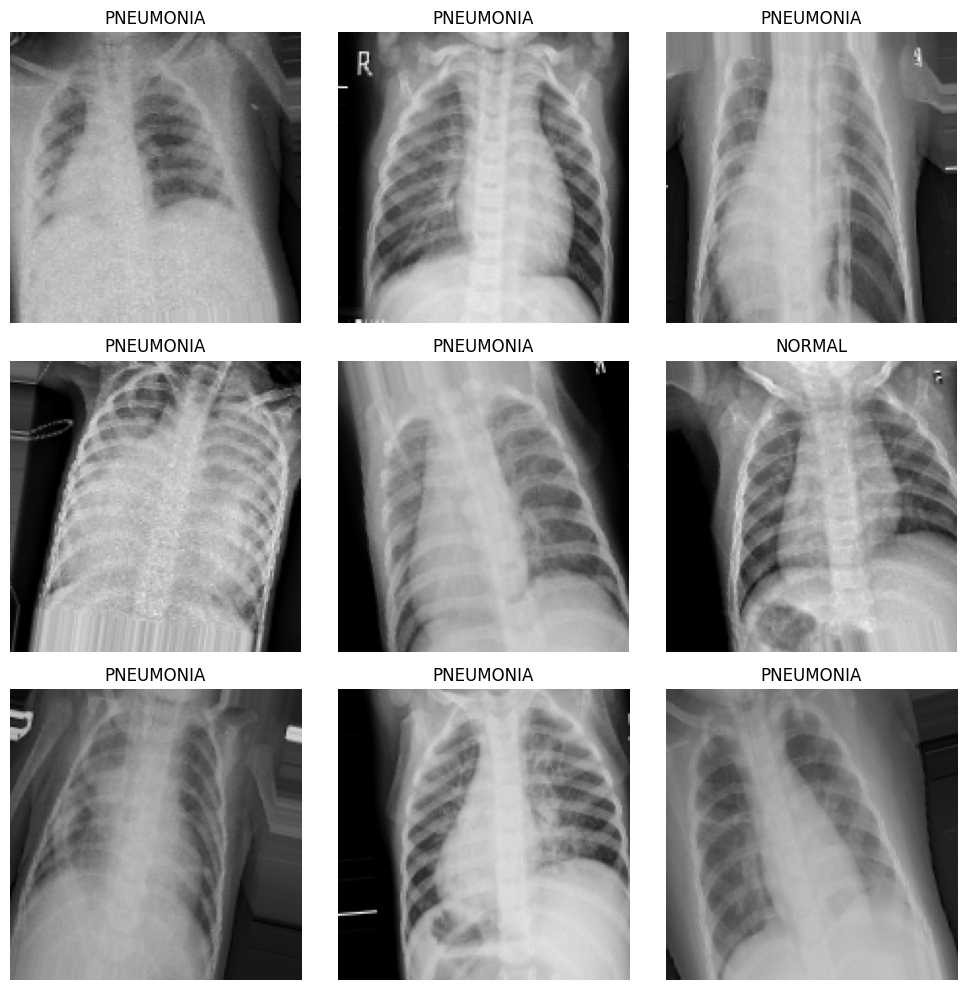

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# get one batch from the training generator
x_batch, y_batch = next(train_gen)

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_batch[i])
    label = "PNEUMONIA" if y_batch[i] == 1 else "NORMAL"
    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()


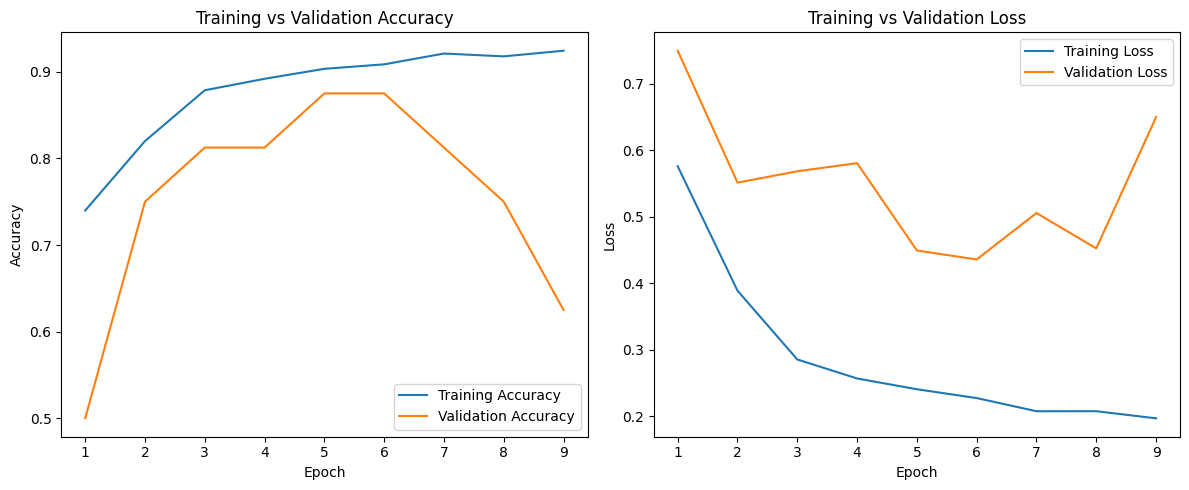

In [ ]:
# history.history is a dict with keys: 'loss', 'val_loss', 'accuracy', 'val_accuracy'
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# get true labels from the generator
y_true = test_gen.classes           # 0 = NORMAL, 1 = PNEUMONIA

# predict probabilities
y_pred_probs = model.predict(test_gen)
# convert probabilities to binary labels
y_pred = (y_pred_probs.flatten() >= 0.5).astype(int)


20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 202ms/step


In [ ]:
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

target_names = list(test_gen.class_indices.keys())
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=target_names))


Confusion Matrix:
 [[209  25]
 [ 52 338]]

Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.80      0.89      0.84       234
   PNEUMONIA       0.93      0.87      0.90       390

    accuracy                           0.88       624
   macro avg       0.87      0.88      0.87       624
weighted avg       0.88      0.88      0.88       624



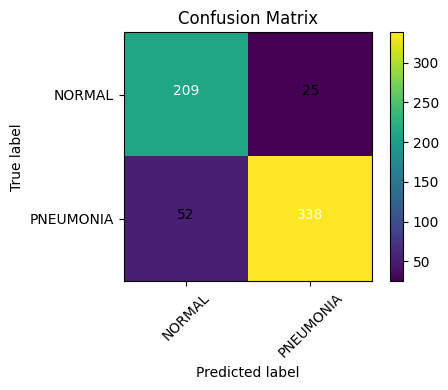

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

classes = list(test_gen.class_indices.keys())

plt.figure(figsize=(5, 4))
plt.imshow(cm, interpolation='nearest')
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

# print numbers inside the boxes
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()


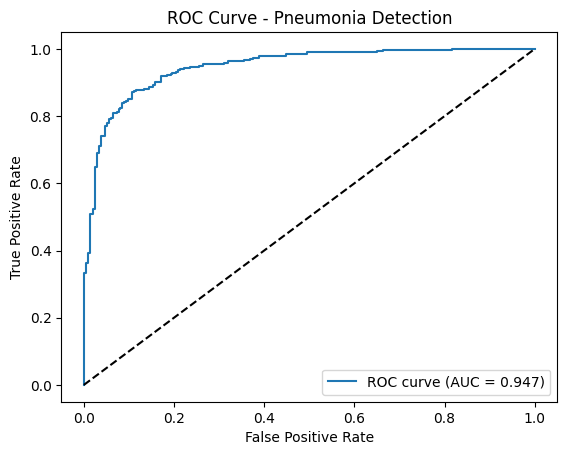

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_true, y_pred_probs)
auc_score = roc_auc_score(y_true, y_pred_probs)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Pneumonia Detection')
plt.legend(loc="lower right")
plt.show()


In [ ]:
model.save("pneumonia_cnn.keras")


In [ ]:
from google.colab import files
files.download("pneumonia_cnn.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>